<a href="https://colab.research.google.com/github/TildeSkar/Applied-Deep-Learning---Physics---exrecises/blob/main/Exercise_7_1_CIFAR_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tabulate import tabulate
layers = tf.keras.layers

The code block below defines a few helper functions to visualize the results. You do not need to touch them.

In [2]:
def plot_examples(X, Y, n=10):
    """ Plot the first n examples for each of the 10 classes in the CIFAR dataset X, Y """
    fig, axes = plt.subplots(n, 10, figsize=(10, n))
    for l in range(10):
        axes[0, l].set_title(cifar10_labels[l], fontsize="smaller")
        m = np.squeeze(Y) == l  # boolean mask: True for all images of label l
        for i in range(n):
            image = X[m][i].astype("uint8")  # imshow expects uint8
            ax = axes[i, l]
            ax.imshow(image, origin="upper")
            ax.set(xticks=[], yticks=[])
    return fig, ax


def plot_prediction(X, Y, Y_predict):
    """
    Plot image X along with predicted probabilities Y_predict.
    X: CIFAR image, shape = (32, 32, 3)
    Y: CIFAR label, one-hot encoded, shape = (10)
    Y_predict: predicted probabilities, shape = (10)
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

    # plot image
    ax1.imshow(X.astype("uint8"), origin="upper")
    ax1.set(xticks=[], yticks=[])

    # plot probabilities
    ax2.barh(np.arange(10), Y_predict, align="center")
    ax2.set(xlim=(0, 1), xlabel="Score", yticks=[])
    for i in range(10):
        c = "red" if (i == np.argmax(Y)) else "black"
        ax2.text(0.05, i, cifar10_labels[i].capitalize(), ha="left", va="center", color=c)



def plot_confusion(Y_true, Y_predict):
    """
    Plot confusion matrix
    Y_true:    array of true classifications (0-9), shape = (N)
    Y_predict: array of predicted classifications (0-9), shape = (N)
    """
    C = np.histogram2d(Y_true, Y_predict, bins=np.linspace(-0.5, 9.5, 11))[0]
    Cn = C / np.sum(C, axis=1)

    fig = plt.figure()
    plt.imshow(Cn, interpolation="nearest", vmin=0, vmax=1, cmap=plt.cm.YlGnBu)
    plt.colorbar()
    plt.xlabel("prediction")
    plt.ylabel("truth")
    plt.xticks(range(10), cifar10_labels, rotation="vertical")
    plt.yticks(range(10), cifar10_labels)
    for x in range(10):
        for y in range(10):
            plt.annotate("%i" % C[x, y], xy=(y, x), ha="center", va="center")



First we load and preprocess CIFAR-10 data. The imagages are 32x32 pixels and have three color channels (red, green blue).

In [3]:

# X: images, Y: labels
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("images, shape = ", x_train.shape)
print("labels, shape = ", y_train.shape)

cifar10_labels = np.array([
    'airplane',
    'automobile',
    'bird',
    'cat',
    'deer',
    'dog',
    'frog',
    'horse',
    'ship',
    'truck'])

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 272s 2us/step
images, shape =  (50000, 32, 32, 3)
labels, shape =  (50000, 1)


(<Figure size 1000x1000 with 100 Axes>, <Axes: >)

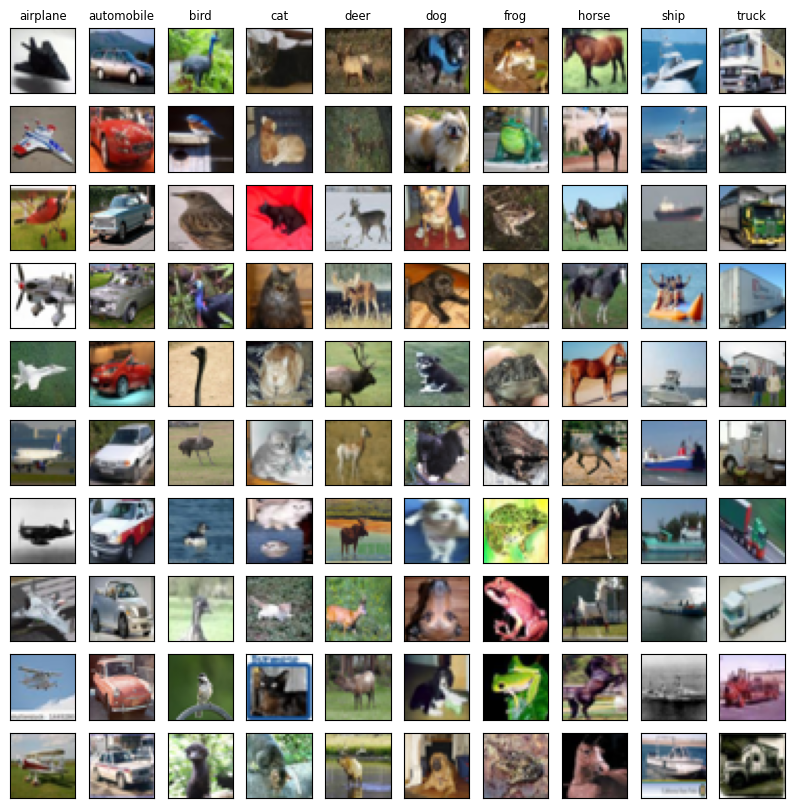

In [4]:
# Plot example images, using the plot examples function

plot_examples(x_train, y_train)

First the data is normalised. Currently the data takes values between 0 and 255. We want to assure it can take float values between 0 and 1 instead it is thus normalized by dividing it by 255.0.

We also use one-hot encoding for the labels. Meaning we convert the labels from 0-9 to: "0" = (1, 0, ... 0) or "1" = (0, 1, ... 0) etc.

In [11]:
# convert labels ("0"-"9") to one-hot encodings, "0" = (1, 0, ... 0) and so on
y_train_onehot = tf.keras.utils.to_categorical(y_train, 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, 10)[:8000]
y_valid_onehot = tf.keras.utils.to_categorical(y_test, 10)[8000:]


# normalize the data
x_train_norm = x_train.astype("float32") / 255
x_test_norm = x_test.astype("float32") / 255

# use 20% of the test data for validation
x_valid_norm = x_test[8000:]
x_test_norm = x_test_norm[:8000]

We start with a fully connected network

In [16]:
# Defining model parameters
dropout_rate = 0.2

# ----------------------------------------------------------
# Define model
# ----------------------------------------------------------
model = tf.keras.models.Sequential()
model.add(layers.Input(shape=(32, 32, 3)))
model.add(layers.Flatten())  # (32,32,3) --> (3072) # flattens the image
 # this time the flatten operation is directly integrated into the network
 # structure so that we can use the same input data later for a convolutional neural network.
model.add(layers.Dense(256, 'relu')) # adding another dense layer
model.add(layers.Dense(256, 'relu')) # adding second dense layer
model.add(layers.Dropout(dropout_rate))  # Add dropout
model.add(layers.Dense(10, activation='softmax')) # final layer
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 855,050 (3.26 MB)

 Trainable params: 855,050 (3.26 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# ----------------------------------------------------------
# Training
# ----------------------------------------------------------
model.compile(
    loss = 'categorical_crossentropy',
    optimizer = 'adam',
    metrics=['accuracy']
)

model.fit(
    x_train_norm, y_train_onehot,
    batch_size= 64,
    epochs=20, # train at least for 20 epochs
    verbose=2,
    validation_data=(x_valid_norm, y_valid_onehot),
    callbacks=[tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))],
)

Epoch 1/20
782/782 - 14s - 19ms/step - accuracy: 0.3195 - loss: 1.8799 - val_accuracy: 0.3720 - val_loss: 187.7863
Epoch 2/20
782/782 - 13s - 16ms/step - accuracy: 0.3937 - loss: 1.6982 - val_accuracy: 0.3885 - val_loss: 177.4280
Epoch 3/20
782/782 - 13s - 16ms/step - accuracy: 0.4214 - loss: 1.6213 - val_accuracy: 0.4015 - val_loss: 191.3004
Epoch 4/20
782/782 - 21s - 26ms/step - accuracy: 0.4356 - loss: 1.5768 - val_accuracy: 0.4380 - val_loss: 158.4322
Epoch 5/20
782/782 - 13s - 16ms/step - accuracy: 0.4472 - loss: 1.5437 - val_accuracy: 0.4190 - val_loss: 198.6274
Epoch 6/20
782/782 - 13s - 16ms/step - accuracy: 0.4593 - loss: 1.5163 - val_accuracy: 0.4130 - val_loss: 183.6080
Epoch 7/20
782/782 - 13s - 16ms/step - accuracy: 0.4664 - loss: 1.4916 - val_accuracy: 0.4150 - val_loss: 195.7390
Epoch 8/20
782/782 - 13s - 16ms/step - accuracy: 0.4754 - loss: 1.4725 - val_accuracy: 0.4150 - val_loss: 195.7567
Epoch 9/20
782/782 - 20s - 25ms/step - accuracy: 0.4807 - loss: 1.4566 - val_acc

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


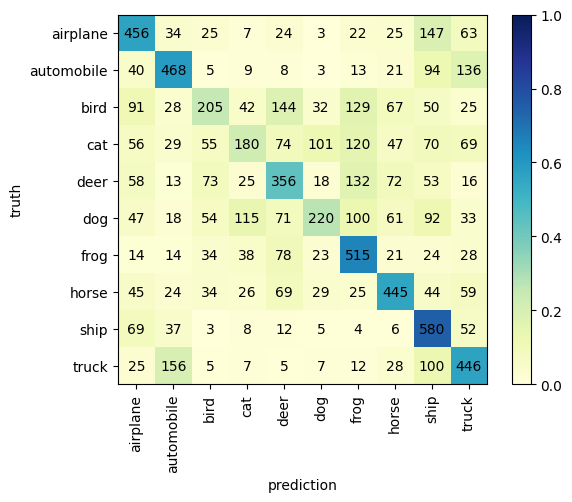

In [20]:
# ----------------------------------------------------------
# Plots
# ----------------------------------------------------------
# training curves
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)


# Plot the confusion matrix for the test data set.
# calculate predictions for test set
y_predict = model.predict(x_test_norm, batch_size=128)

# convert back to class labels (0-9)
y_predict_cl = np.argmax(y_predict, axis=1)
y_test_cl = np.argmax(y_test_onehot, axis=1)

# plot confusion matrix
plot_confusion(y_test_cl, y_predict_cl)

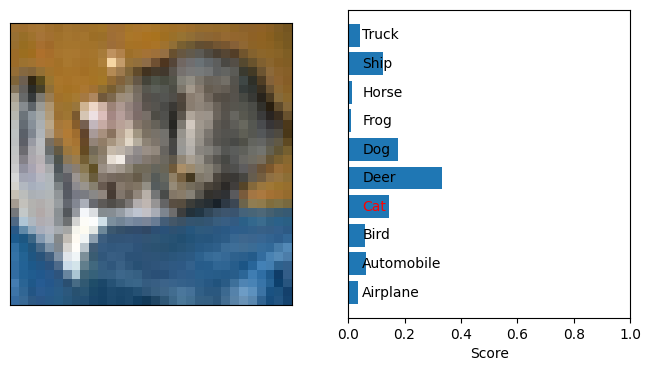

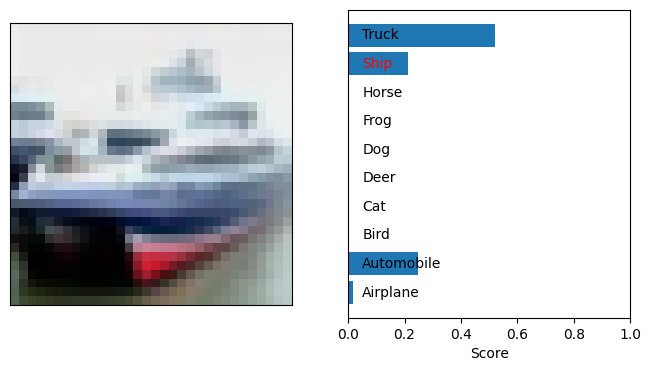

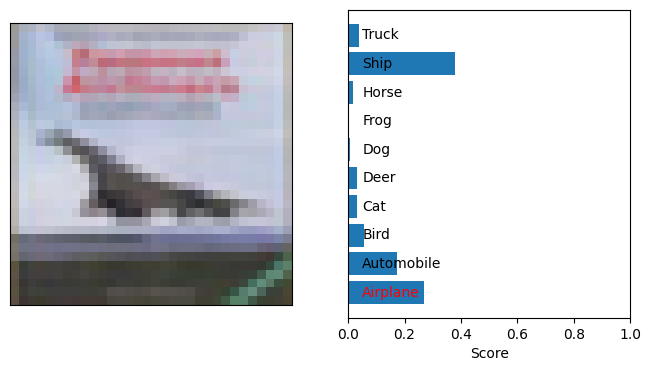

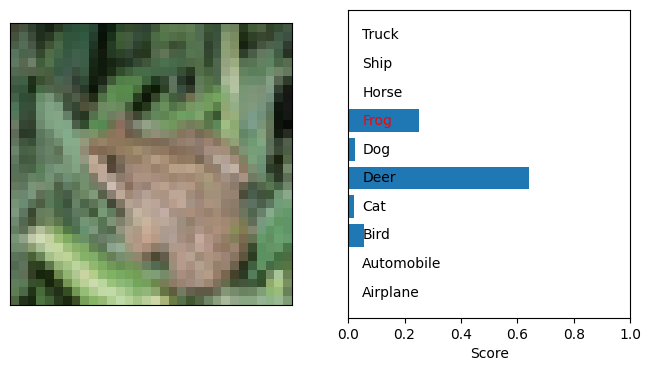

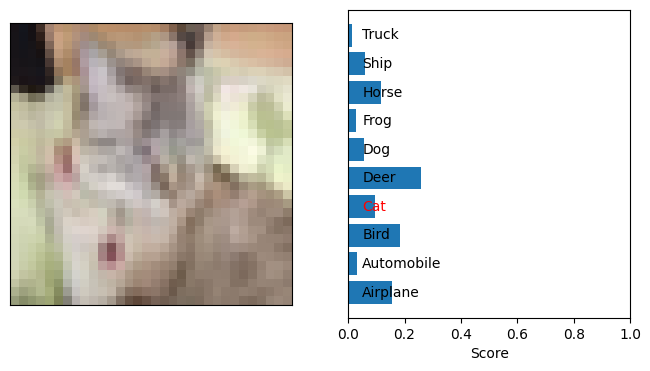

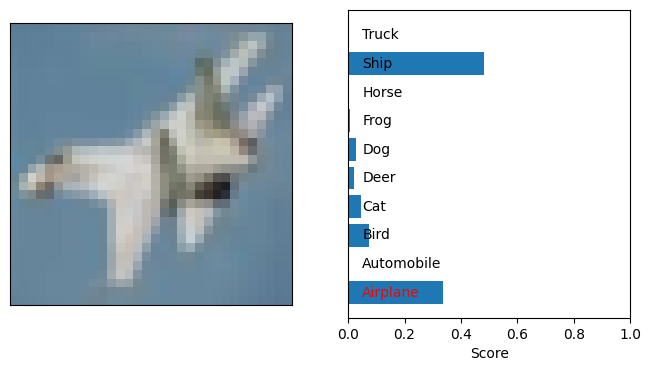

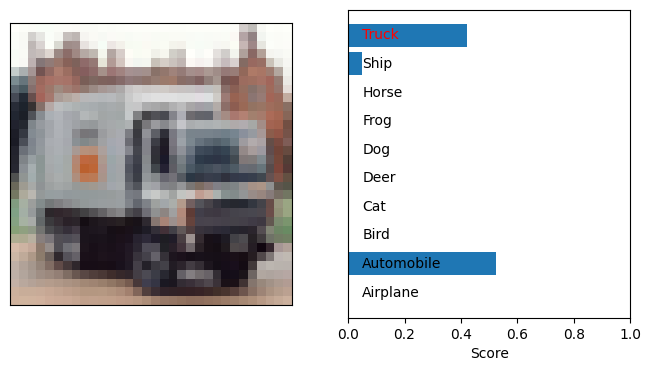

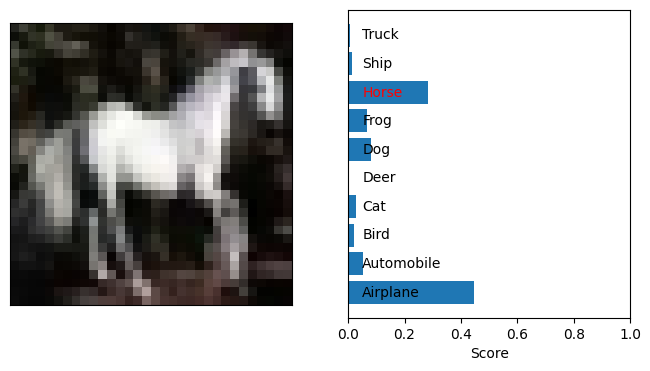

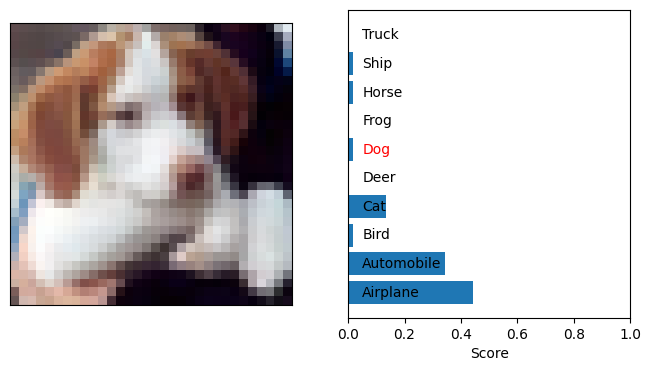

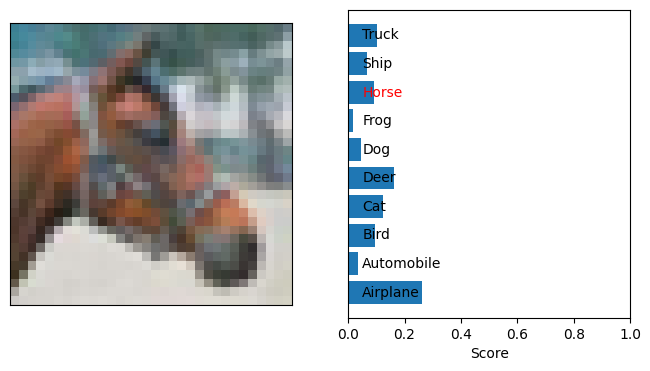

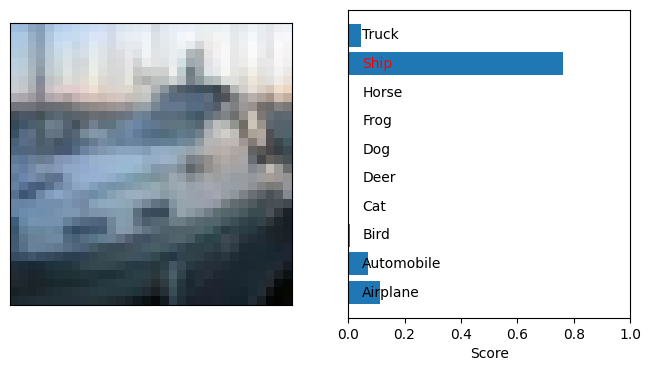

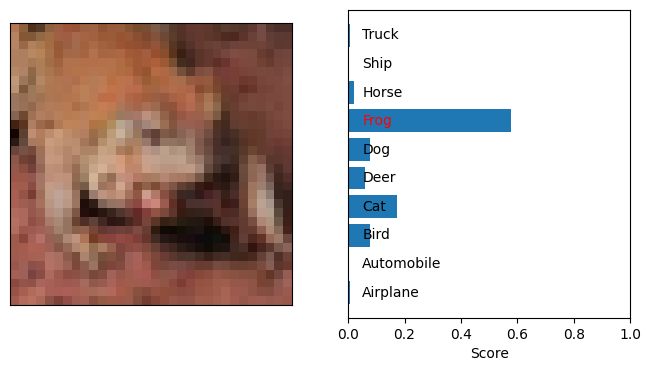

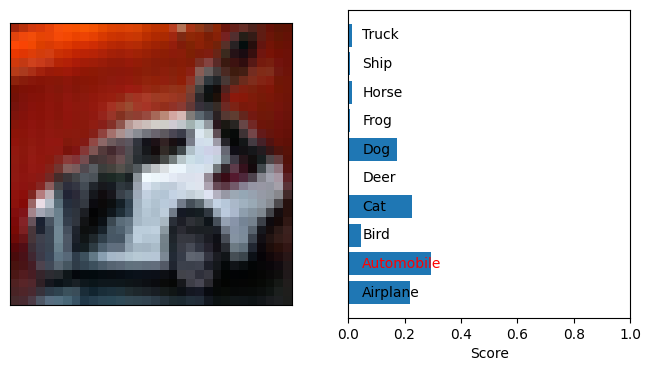

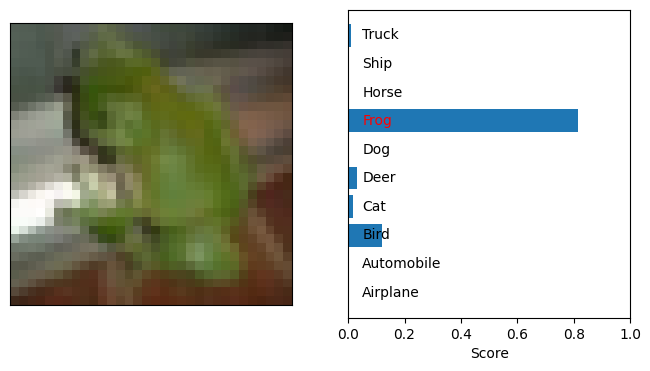

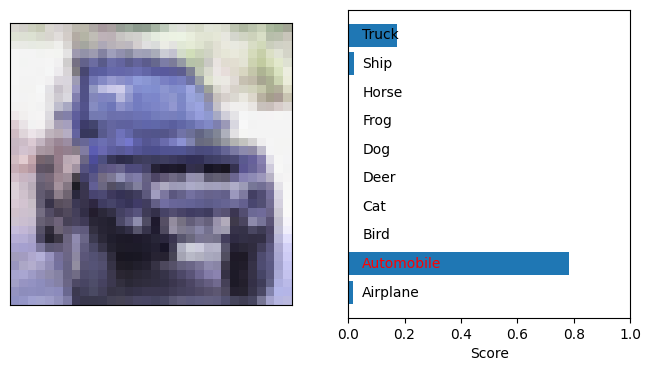

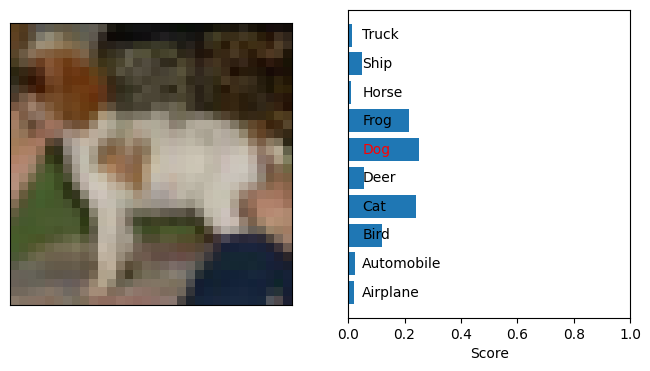

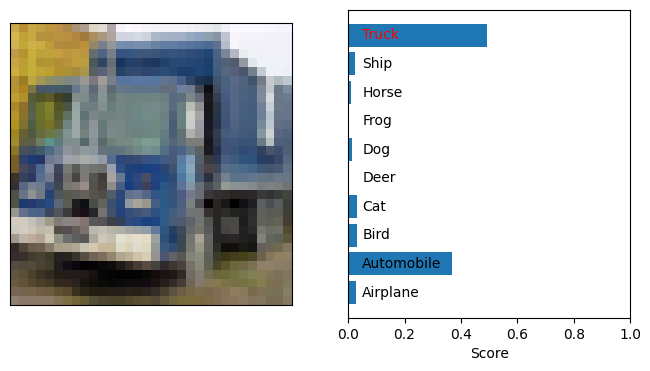

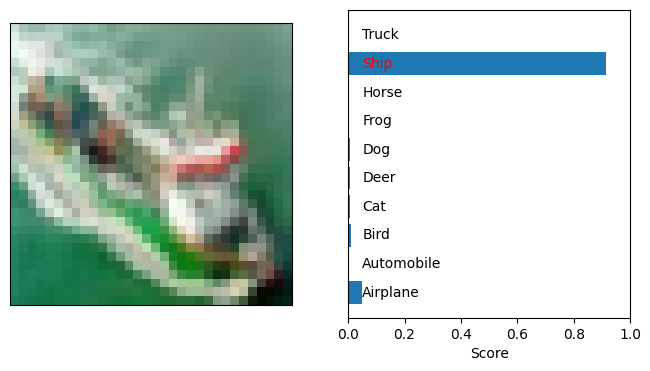

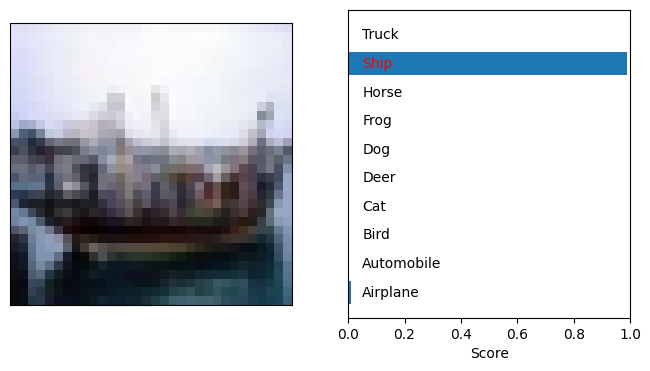

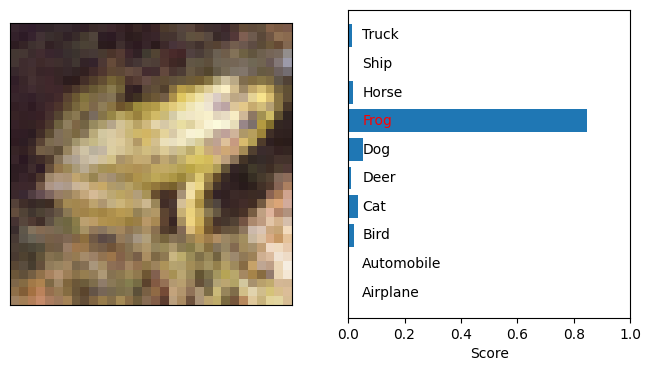

In [22]:
# Task: plot a few examples of correctly and incorrectly classified images.
# Hint: First find the indices of correctly and incorrectly classified images:
m = y_predict_cl == y_test_cl
i0 = np.arange(8000)[~m]  # misclassified images
i1 = np.arange(8000)[m]  # correctly classified images

# original (unnormalized) test images
x_test = x_test[:8000]

# Hint: Now you can use the `plot_prediction` function to plot the images:
# plot first 10 false classifications
for i in i0[0:10]:
    plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])

# Next we plot 10 correctly classified images
for i in i1[0:10]:
    plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])

In [23]:
# Here we quote the achived accuracy on the training, validation and test data sets
train_loss, train_acc = model.evaluate(x_train_norm, y_train_onehot, verbose=0)
valid_loss, valid_acc = model.evaluate(x_valid_norm, y_valid_onehot, verbose=0)
test_loss, test_acc = model.evaluate(x_test_norm, y_test_onehot, verbose=0)

print(f'Training accuracy: {train_acc}, Training loss: {train_loss}')
print(f'Validation accuracy: {valid_acc}, Validation loss: {valid_loss}')
print(f'Test accuracy: {test_acc}, Test loss: {test_loss}')

Training accuracy: 0.5292199850082397, Training loss: 1.3104937076568604
Validation accuracy: 0.4074999988079071, Validation loss: 217.8750457763672
Test accuracy: 0.48387500643730164, Test loss: 1.455320954322815


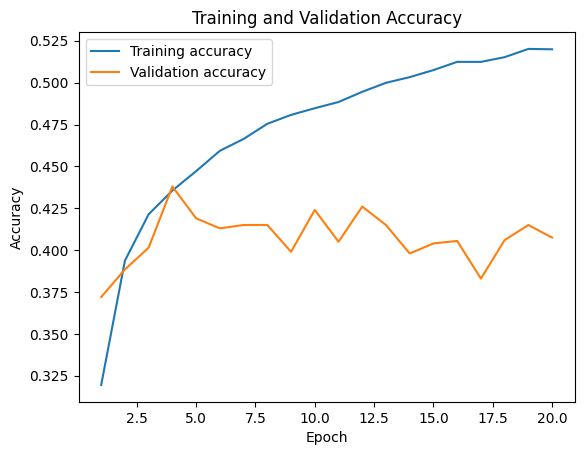

In [24]:
# We plot the training and validation accuracy vs epoch

epochs = range(1, len(history['accuracy']) + 1) # assure plot starts on epoch 1 and not 0

plt.plot(epochs, history['accuracy'], label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

**CNN**
In the second part of this exercise, classify the images with a CNN.


In [26]:
# Hint: this code snipped shows how to define convolution and maxpooling layers. For more information see
# https://keras.io/api/layers/convolution_layers/convolution2d/
# https://keras.io/api/layers/pooling_layers/max_pooling2d/
model = tf.keras.models.Sequential(
    [
        layers.Conv2D(16, kernel_size=(3, 3), padding="same", activation="relu", input_shape=(32, 32, 3)), # first layer
        layers.MaxPooling2D((2, 2), strides=(2, 2)), # adding a maxpooling layer
        layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"), # second convolutional layer
        layers.MaxPooling2D((2, 2), strides=(2, 2)), # second max pooling layer
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(10, activation='softmax') # final layer
    ],
    name="cnn",
)

print(model.summary())

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │        20,490 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,578 (99.91 KB)

 Trainable params: 25,578 (99.91 KB)

 Non-trainable params: 0 (0.00 B)

None


In [28]:
# ----------------------------------------------------------
# Training
# ----------------------------------------------------------
model.compile(
    loss = 'categorical_crossentropy',
    optimizer = 'adam',
    metrics=['accuracy']
)

model.fit(
    x_train_norm, y_train_onehot,
    batch_size= 64,
    epochs=40,
    verbose=2,
    validation_data=(x_valid_norm, y_valid_onehot),
    callbacks=[tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))],
)

Epoch 1/40
782/782 - 51s - 65ms/step - accuracy: 0.7355 - loss: 0.7559 - val_accuracy: 0.4755 - val_loss: 168.9885
Epoch 2/40
782/782 - 76s - 98ms/step - accuracy: 0.7378 - loss: 0.7525 - val_accuracy: 0.4400 - val_loss: 179.7031
Epoch 3/40
782/782 - 83s - 106ms/step - accuracy: 0.7392 - loss: 0.7486 - val_accuracy: 0.4920 - val_loss: 147.6032
Epoch 4/40
782/782 - 82s - 105ms/step - accuracy: 0.7374 - loss: 0.7498 - val_accuracy: 0.3950 - val_loss: 221.4305
Epoch 5/40
782/782 - 44s - 57ms/step - accuracy: 0.7394 - loss: 0.7436 - val_accuracy: 0.4460 - val_loss: 196.9228
Epoch 6/40
782/782 - 45s - 57ms/step - accuracy: 0.7407 - loss: 0.7419 - val_accuracy: 0.4655 - val_loss: 185.0334
Epoch 7/40
782/782 - 82s - 105ms/step - accuracy: 0.7378 - loss: 0.7459 - val_accuracy: 0.4395 - val_loss: 196.1508
Epoch 8/40
782/782 - 44s - 56ms/step - accuracy: 0.7411 - loss: 0.7408 - val_accuracy: 0.4600 - val_loss: 173.5671
Epoch 9/40
782/782 - 86s - 110ms/step - accuracy: 0.7417 - loss: 0.7385 - val

In [29]:
history = np.genfromtxt("history_{}.csv".format(model.name), delimiter=",", names=True)

# Here we quote the achived accuracy on the training, validation and test data sets
train_loss, train_acc = model.evaluate(x_train_norm, y_train_onehot, verbose=0)
valid_loss, valid_acc = model.evaluate(x_valid_norm, y_valid_onehot, verbose=0)
test_loss, test_acc = model.evaluate(x_test_norm, y_test_onehot, verbose=0)

print(f'Training accuracy: {train_acc}, Training loss: {train_loss}')
print(f'Validation accuracy: {valid_acc}, Validation loss: {valid_loss}')
print(f'Test accuracy: {test_acc}, Test loss: {test_loss}')

Training accuracy: 0.8025400042533875, Training loss: 0.5718498229980469
Validation accuracy: 0.44850000739097595, Validation loss: 186.57757568359375
Test accuracy: 0.7162500023841858, Test loss: 0.8328551650047302


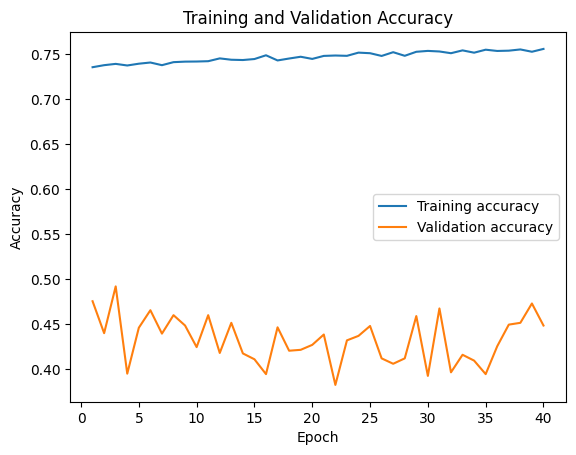

In [30]:
# We plot the training and validation accuracy vs epoch

epochs = range(1, len(history['accuracy']) + 1) # assure plot starts on epoch 1 and not 0

plt.plot(epochs, history['accuracy'], label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

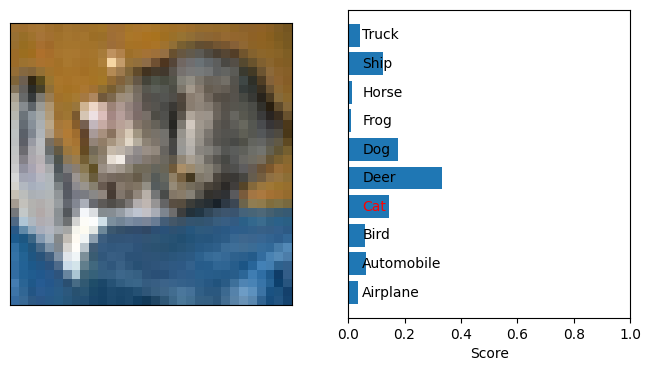

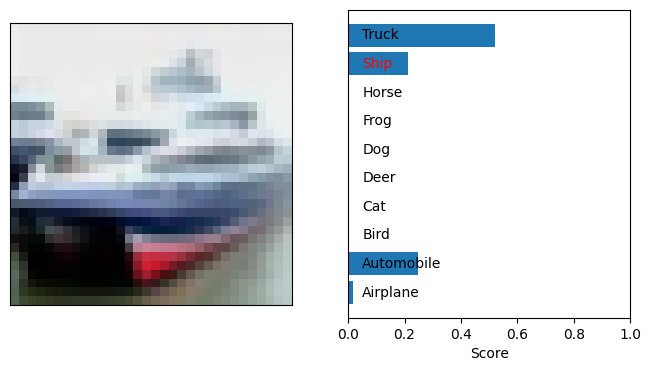

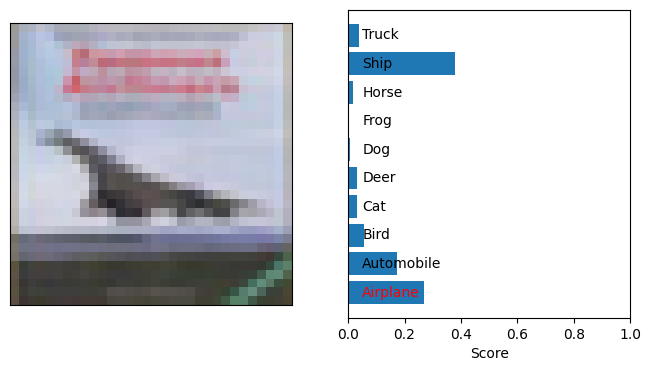

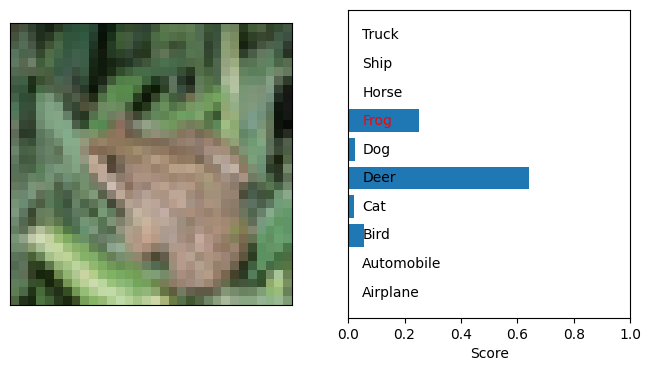

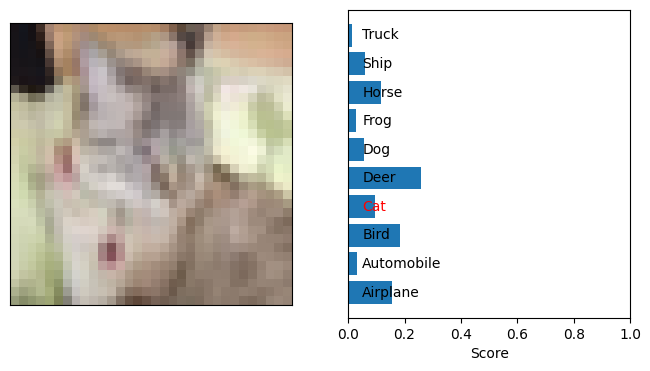

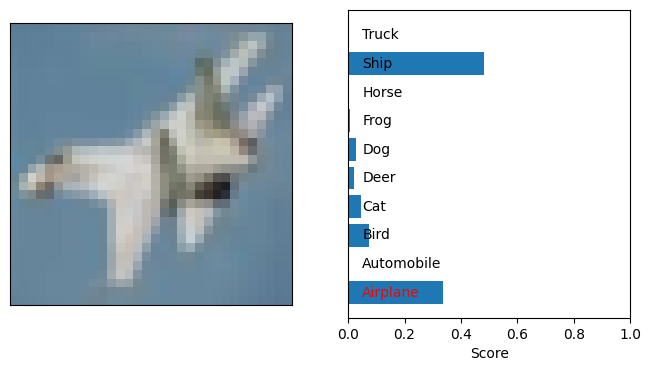

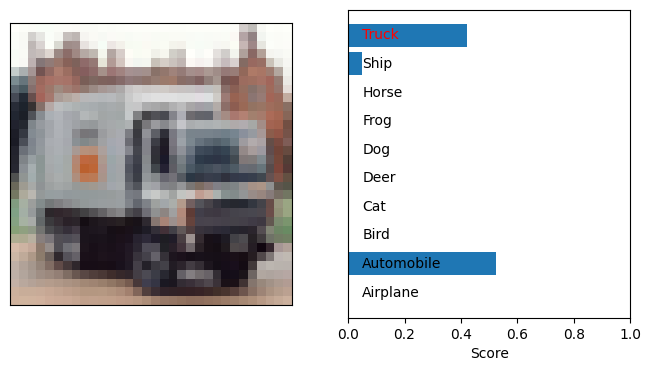

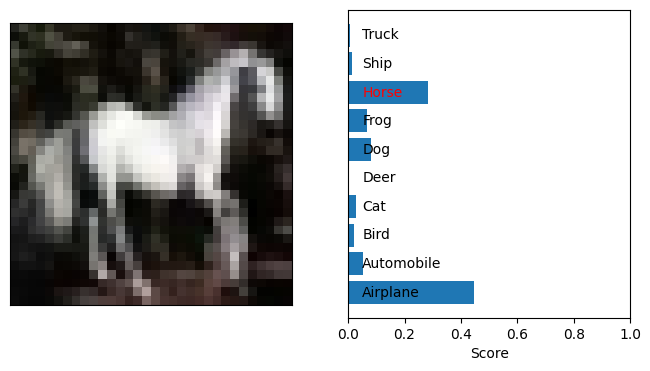

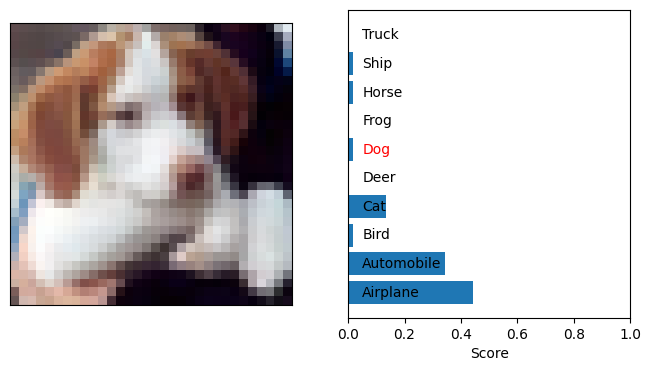

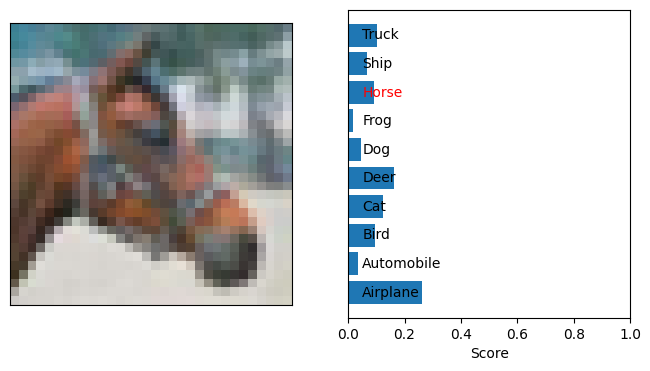

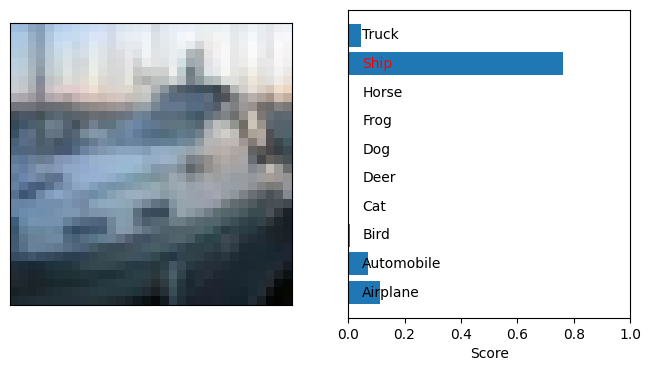

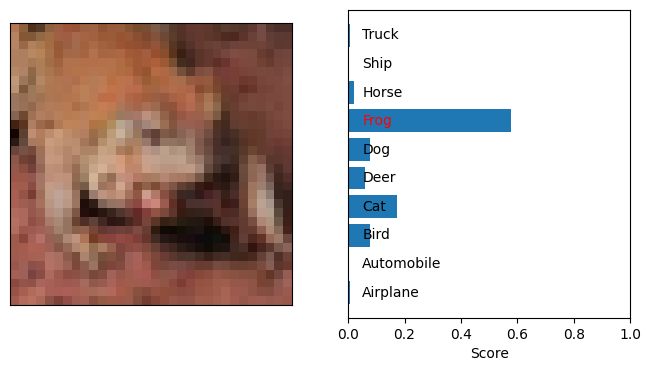

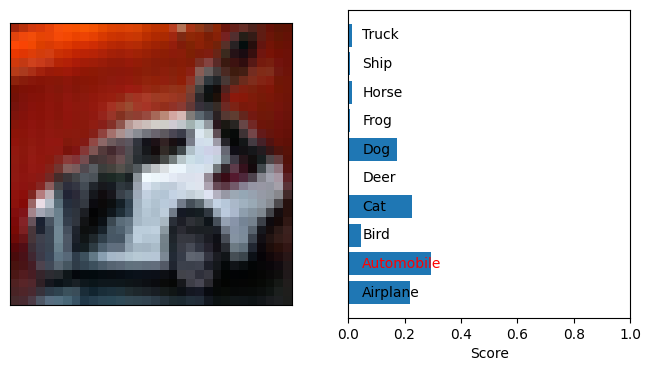

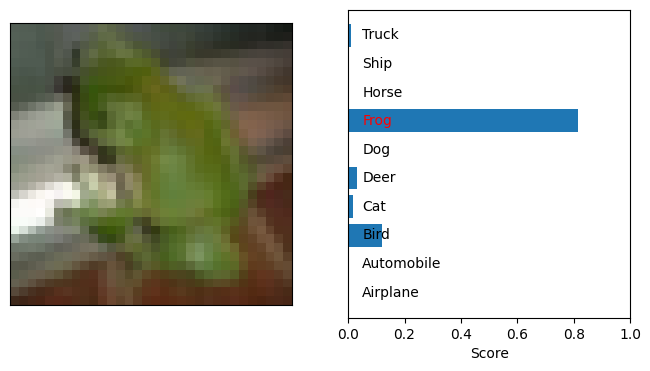

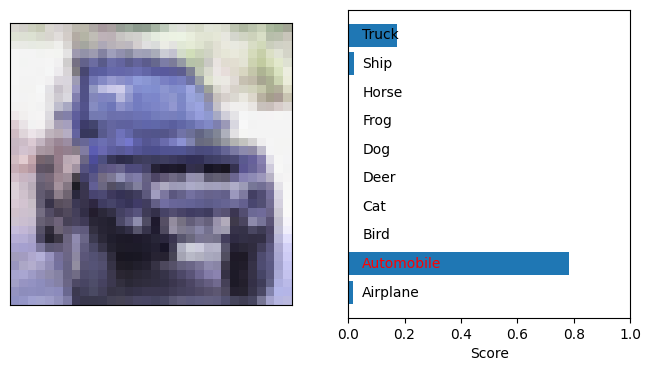

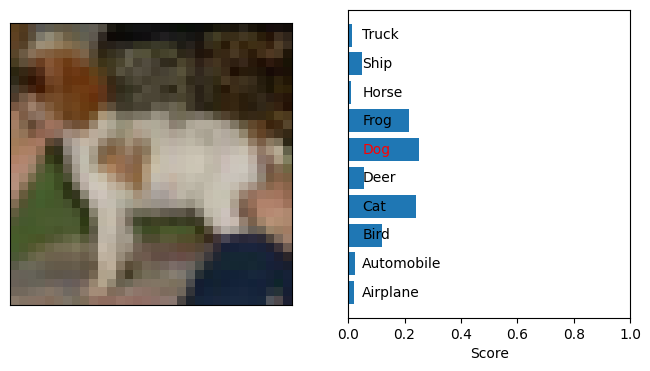

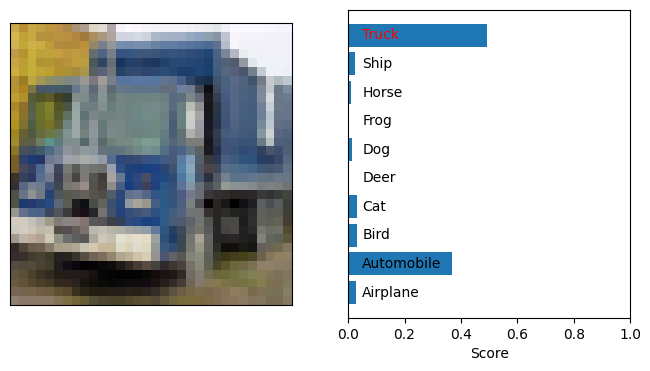

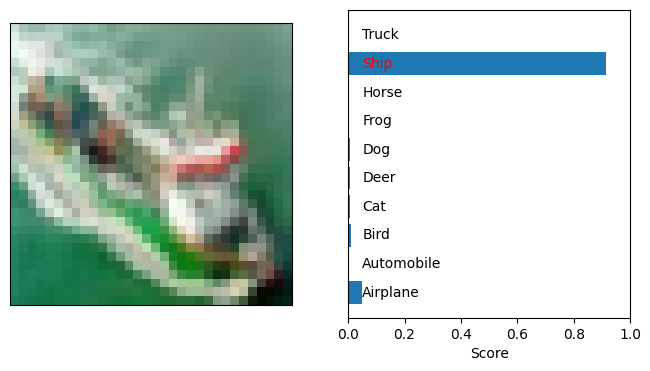

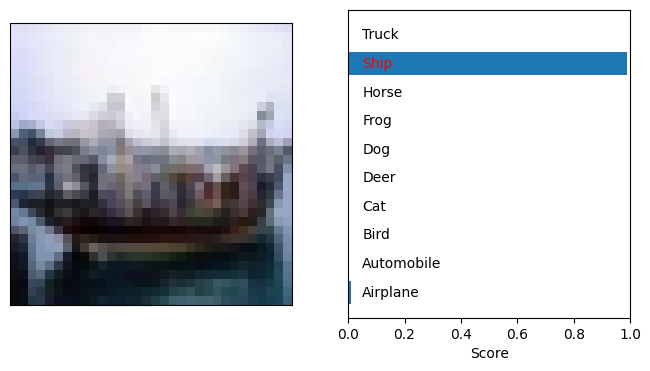

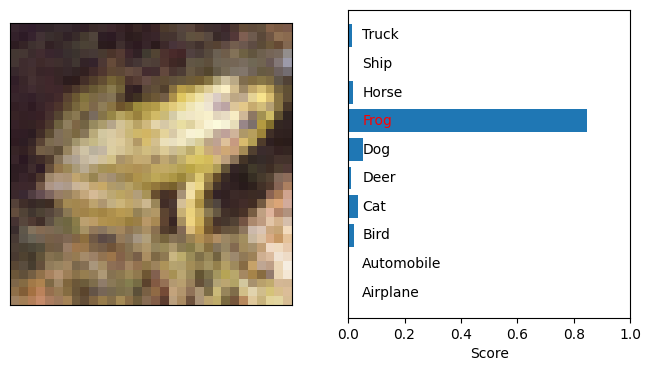

In [31]:
# Task: plot a few examples of correctly and incorrectly classified images.
# Hint: First find the indices of correctly and incorrectly classified images:
m = y_predict_cl == y_test_cl
i0 = np.arange(8000)[~m]  # misclassified images
i1 = np.arange(8000)[m]  # correctly classified images

# original (unnormalized) test images
x_test = x_test[:8000]

# Hint: Now you can use the `plot_prediction` function to plot the images:
# plot first 10 false classifications
for i in i0[0:10]:
    plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])

# Next we plot 10 correctly classified images
for i in i1[0:10]:
    plot_prediction(x_test[i], y_test_onehot[i], y_predict[i])

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step


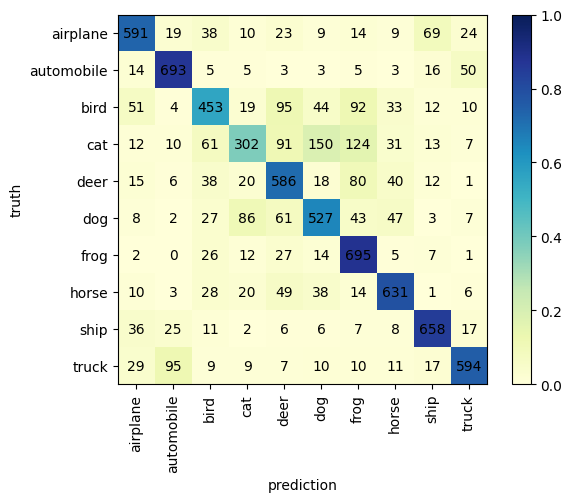

In [32]:
# Plot the confusion matrix for the test data set.
# calculate predictions for test set
y_predict = model.predict(x_test_norm, batch_size=128)

# convert back to class labels (0-9)
y_predict_cl = np.argmax(y_predict, axis=1)
y_test_cl = np.argmax(y_test_onehot, axis=1)

# plot confusion matrix
plot_confusion(y_test_cl, y_predict_cl)